In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import shutil
from scipy.signal import savgol_filter
import pandas as pd
from pathlib import Path
import re
import pyarrow.feather as feather

from random import randint

### Set global variables

In [2]:
SAVEFILES = True
OVERWRITE = False

SAVEDIR = Path("~/ECM_mod_output/").expanduser()
    
LYAP_DIR = Path(SAVEDIR,'Lyap_analysis')
LYAP_DIR.mkdir(parents=True, exist_ok=True)

USE_ORIGINAL = True # set to true to automatically download the original data from Dropbox

rcParams.update({'figure.autolayout': True})

### Load UMAP embedding of Lyapunov data
UMAP embeddings should be `LYAP_DIR`. If they are not detected, they will be downloaded automatically.  

NOTE: Compressed LYAP_DIR data is ~50 MB. 

In [3]:
LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f and 'embedding_' in f]   
if len(LYAP_filepaths) < 2000 or USE_ORIGINAL:
    print(f'Could not find Lyapnunov data; downloading to {LYAP_DIR}')
    !wget -O LYAP.zip 'https://www.dropbox.com/s/r7inxffpdssm1dq/Lyap_analysis.zip?dl=1'
    !unzip LYAP.zip
    shutil.rmtree(LYAP_DIR)
    shutil.move('./Lyap_analysis/', SAVEDIR)
    os.remove('./LYAP.zip')
    LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f and 'embedding_' in f]   

LYAP_filepaths.sort()

Could not find Lyapnunov data; downloading to /Users/darren/ECM_mod_output/Lyap_analysis
--2024-07-23 15:22:11--  https://www.dropbox.com/scl/fi/hjtuejngyqe78k45utaj7/Lyap_analysis.zip?rlkey=vtl48j839zys324lpnije58nd&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.9.18, 2620:100:601f:18::a27d:912
Connecting to www.dropbox.com (www.dropbox.com)|162.125.9.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc178e741940bb570044bcc0e38a.dl.dropboxusercontent.com/cd/0/inline/CXTVEeSKM3V2E9lVdGFo4gIo16mFTNxQPkDGs5SWWCTM4KigavcPUobGqxq1Iz-le28VIhGiy9dMtC4we-K2rI4b0OfYaOAb5tUEcZEeoMKQMzNb20FSvXGNazC54Q8C7_D5BadGp10fvKJzuRIpeMzd/file?dl=1# [following]
--2024-07-23 15:22:12--  https://uc178e741940bb570044bcc0e38a.dl.dropboxusercontent.com/cd/0/inline/CXTVEeSKM3V2E9lVdGFo4gIo16mFTNxQPkDGs5SWWCTM4KigavcPUobGqxq1Iz-le28VIhGiy9dMtC4we-K2rI4b0OfYaOAb5tUEcZEeoMKQMzNb20FSvXGNazC54Q8C7_D5BadGp10fvKJzuRIpeMzd/file?dl=1
Resolving uc178e741940bb570044bcc0e3

In [4]:
LYAP_filepaths[:5]

['/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_000.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_001.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_002.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_003.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_004.csv']

In [5]:
filenames_erl = [f for f in LYAP_filepaths if 'erl' in f]
filenames_erl.sort()

ode_divs_erl = np.genfromtxt(Path(LYAP_DIR,'erl_IMT.csv'), delimiter=',')
# ode_divs_erl = np.genfromtxt(Path(SAVEDIR,'ODE_output','ERL_IMT.csv'), delimiter=',') # this works if data generated by ??
# ode_divs_erl = feather.read_feather(Path(SAVEDIR,'mINT_ERL_cycdi_0_0.fea'))[0].to_numpy() # data generated by Fig4/run_lyaps.ipynb currently does not work!!


lyap_erl = np.genfromtxt(Path(LYAP_DIR,'lyap_erl.csv'), delimiter=',')

In [6]:
filenames_dmso = [f for f in LYAP_filepaths if 'dmso' in f]
filenames_dmso.sort()

ode_divs_dmso = np.genfromtxt(Path(LYAP_DIR,'dmso_IMT.csv'), delimiter=',')
lyap_dmso = np.genfromtxt(Path(LYAP_DIR,'lyap_dmso.csv'), delimiter=',')

In [7]:
assert len(filenames_dmso) == len(filenames_erl) == 1000

In [8]:
all_divs = np.concatenate((ode_divs_erl, ode_divs_dmso))
ode_max = max(all_divs)
ode_min = min(all_divs)


In [9]:
tmp_emb = np.genfromtxt(filenames_erl[600], delimiter=',')
tmp_l = len(tmp_emb)

In [10]:
size = (8,4)
xmin = -10
xmax = 15
ymin = 0
ymax = 18
wid = 1

norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

/Users/darren/miniforge3/envs/ECM_model/lib/python3.10/site-packages/IPython/core/events.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
/Users/darren/miniforge3/envs/ECM_model/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


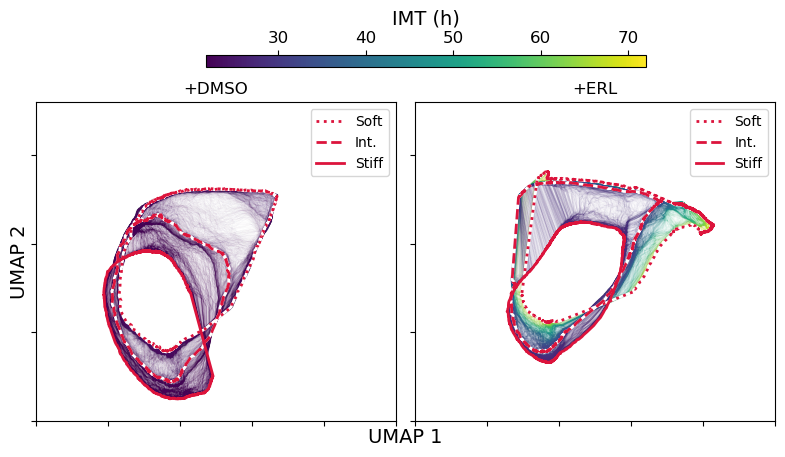

<Figure size 640x480 with 0 Axes>

In [11]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_dmso[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_erl[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
# tmp_l = int(len(tmp_emb))
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = 600
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])

tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = 430
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)    

axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', location='top', label='IMT (h)')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVEDIR, 'fig4a.png')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [12]:
norm = plt.Normalize(-0.04, 0)
cm = plt.cm.cividis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

### Downsample ODE trajectories to 1/10 (100 trajectories)

In [13]:
filenames_dmso_100 = filenames_dmso[0::10]
filenames_erl_100 = filenames_erl[0::10]

In [14]:
len(filenames_erl_100)

100

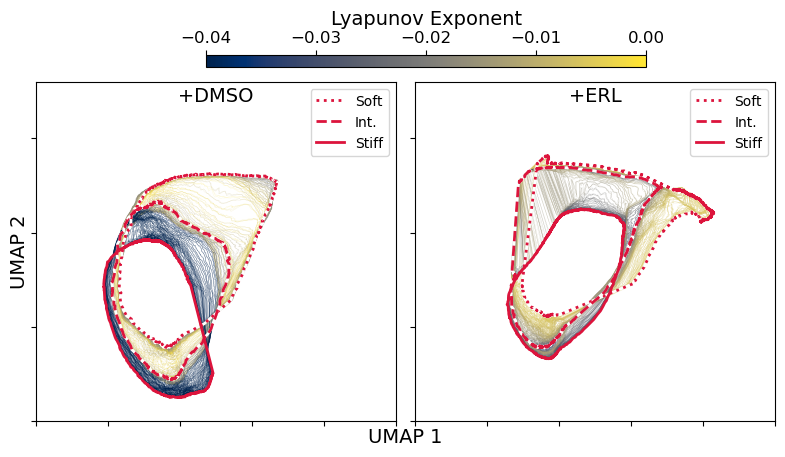

<Figure size 640x480 with 0 Axes>

In [15]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_dmso[ii])), lw=0.1, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_erl[ii])), lw=0.1, alpha=0.5)
    ii+=1
    

    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = 600
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    


tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = 430
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)     


axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, ticks=[-0.04, -0.03, -0.02, -0.01, 0], 
             orientation='horizontal', location='top', label='Lyapunov Exponent')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVEDIR, 'fig4a_lyap.png')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [16]:
ode_divs_erl[0]

72.05

In [17]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 24,
         'axes.titlesize': 24,
         'axes.edgecolor': "black",
         'xtick.labelsize': 20,
         'ytick.labelsize': 20}
plt.rcParams.update(params)

(-0.1, 0.02)

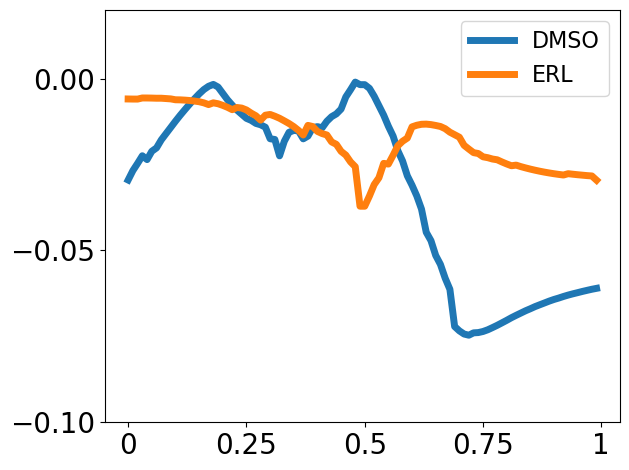

In [18]:
plt.plot(lyap_dmso, label="DMSO", lw=5)
plt.plot(lyap_erl, label='ERL', lw=5)
plt.legend(fontsize=16)
locs, labels = plt.xticks() 
plt.xticks([0, 25, 50, 75, 100], [0, 0.25, 0.5, 0.75, 1])
plt.yticks([-0.1, -0.05, 0])

plt.ylim(-0.1, 0.02)